# Hierarchical Forecast | NeuralForecast

> A minimal example of using Hierarchical Forecast with NeuralForecast\

Tourism-L

This notebook offers a step by step guide to create a hierarchical forecasting pipeline.

In the pipeline we will use `NeuralForecast` and `HINT` class, to create fit, predict and reconcile forecasts.

We will use the TourismL dataset that summarizes large Australian national visitor survey.

Outline<br>
1. Installing packages<br>
2. Load hierarchical dataset<br>
3. Fit and Predict HINT<br>
4. Benchmark methods<br>
5. Forecast Evaluation

You can run these experiments using GPU with Google Colab.

<a href="https://colab.research.google.com/github/Nixtla/neuralforecast/blob/main/nbs/docs/tutorials/hierarchical_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Installing packages

In [ ]:
%%capture
!pip install datasetsforecast hierarchicalforecast neuralforecast statsforecast

## 2. Load hierarchical dataset
### 資料欄位、階層關係、時間序列的規律

This detailed Australian Tourism Dataset comes from the National Visitor Survey, managed by the Tourism Research Australia, it is composed of 555 monthly series from 1998 to 2016, it is organized geographically, and purpose of travel. The natural geographical hierarchy comprises seven states, divided further in 27 zones and 76 regions. The purpose of travel categories are holiday, visiting friends and relatives (VFR), business and other. The MinT (Wickramasuriya et al., 2019), among other hierarchical forecasting studies has used the dataset it in the past. The dataset can be accessed in the [MinT reconciliation webpage](https://robjhyndman.com/publications/mint/), although other sources are available.

這裡相加的是「有幾條序列」，不是把旅遊量加兩次。
你擔心的重複計算，若是在加「旅遊量」，確實會發生；這張表只是在數「序列條數」。

為什麼兩種都保留？因為我們可能同時想知道「全澳洲下個月的總旅遊量」和「其中商務旅遊有多少」。它們回答不同問題，但彼此有加總關係，階層式預測就要處理這種關係。

| Geographical Division | Number of series per division | Number of series per purpose | Total |
|          ---          |               ---             |              ---             |  ---  |
|  Australia            |              1                |               4              |   5   |
|  States               |              7                |              28              |  35   |
|  Zones                |             27                |              108             |  135  |
|  Regions              |             76                |              304             |  380  |
|  Total                |            111                |              444             |  555  |


In [ ]:
import pandas as pd # 處理表格資料

from datasetsforecast.hierarchical import HierarchicalData # 載入階層式時間序列資料集
from hierarchicalforecast.utils import aggregate, HierarchicalPlot # 底層資料加總成不同階層 繪製階層圖表
from neuralforecast.utils import augment_calendar_df # 增加時間特徵
from utilsforecast.plotting import plot_series # 畫一般的時間序列圖

In [ ]:
# Load hierarchical dataset
Y_df, S_df, tags = HierarchicalData.load('./data', 'TourismLarge')
Y_df['ds'] = pd.to_datetime(Y_df['ds']) #ds 是 Date Stamp 的縮寫

Y_df, _ = augment_calendar_df(df=Y_df, freq='M')
S_df = S_df.reset_index(names="unique_id")

# 讓 unique_id 的順序跟 S 矩陣一致，否則 HINT 的 BottomUp 會把錯的序列加總
order = S_df['unique_id'].tolist()
Y_df['unique_id'] = pd.Categorical(Y_df['unique_id'], categories=order, ordered=True)
Y_df = Y_df.sort_values(['unique_id', 'ds']).reset_index(drop=True)


"""
變數	意義
Y_df	真正的時間序列資料(所有層的)
S_df	階層加總矩陣，提供 HINT 使用
tags	各個階層有哪些序列
"""

# 查看 HierarchicalData 類別的成員名稱
print(dir(HierarchicalData))

print("=== Y_df ===")
print("欄位名稱:", Y_df.columns.tolist())
print(Y_df.head())

print("\n=== S_df ===")
print("欄位名稱:", S_df.columns.tolist())
print(S_df.iloc[:5, :8])

print("\n=== tags ===")
print("階層名稱:", list(tags.keys()))

print("\n=== 資料形狀 ===")
print("Y_df:", Y_df.shape)
print("S_df:", S_df.shape)

100%|██████████| 1.30M/1.30M [00:01<00:00, 1.15MiB/s]
100%|██████████| 335k/335k [00:00<00:00, 496kiB/s]
100%|██████████| 968k/968k [00:01<00:00, 858kiB/s]


['__annotations__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', 'download', 'load', 'source_url', 'source_url_old_tourisml', 'source_url_old_traffic']
=== Y_df ===
欄位名稱: ['unique_id', 'ds', 'y', 'month']
  unique_id         ds             y     month
0  TotalAll 1998-01-01  45151.071280 -0.500000
1  TotalAll 1998-02-01  17294.699551 -0.409091
2  TotalAll 1998-03-01  20725.114184 -0.318182
3  TotalAll 1998-04-01  25388.612353 -0.227273
4  TotalAll 1998-05-01  20330.035211 -0.136364

=== S_df ===
欄位名稱: ['unique_id', 'AAAHol', 'AAAVis', 'AAABus', 'AAAOth', 'AABHol', 'AABVis', 'AABBus', 'AABOth', 'ABAHol', 'ABAVis', 'ABABus', 'ABAOth', 

In [ ]:
print(Y_df['unique_id'].unique()[:20])
print(tags.keys())

# 最底層是：
# Country/State/Zone/Region/Purpose
# 也就是 某個州 → 某個區域 → 某個地區 → 某種旅遊目的 的人數。

['TotalAll', 'AAll', 'BAll', 'CAll', 'DAll', ..., 'BBAll', 'BCAll', 'BDAll', 'BEAll', 'CAAll']
Length: 20
Categories (555, object): ['TotalAll' < 'AAll' < 'BAll' < 'CAll' ... 'GBDHol' < 'GBDVis' < 'GBDBus' <
                           'GBDOth']
dict_keys(['Country', 'Country/State', 'Country/State/Zone', 'Country/State/Zone/Region', 'Country/Purpose', 'Country/State/Purpose', 'Country/State/Zone/Purpose', 'Country/State/Zone/Region/Purpose'])


Mathematically a hierarchical multivariate time series can be denoted by the vector $\mathbf{y}_{[a,b],t}$ defined by the following aggregation constraint:

$$
\mathbf{y}_{[a,b],t}  = \mathbf{S}_{[a,b][b]} \mathbf{y}_{[b],t} \quad \Leftrightarrow \quad
\begin{bmatrix}\mathbf{y}_{[a],t}
\\ %\hline
\mathbf{y}_{[b],t}\end{bmatrix}
= \begin{bmatrix}
\mathbf{A}_{[a][b]}\\ %\hline
\mathbf{I}_{[b][b]}
\end{bmatrix}
\mathbf{y}_{[b],t}
$$

where $\mathbf{y}_{[a],t}$ are the aggregate series, $\mathbf{y}_{[b],t}$ are the bottom level series and $\mathbf{S}_{[a,b][b]}$ are the hierarchical aggregation constraints.

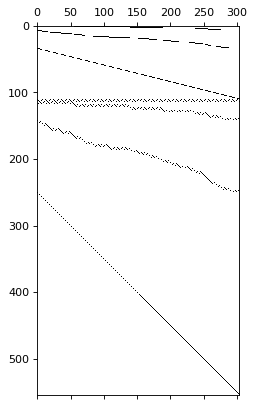

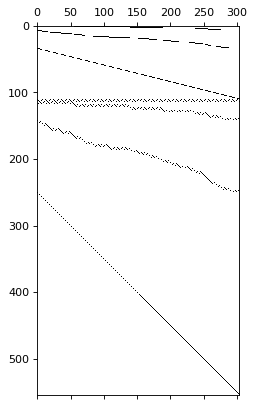

In [ ]:
# Here we plot the hierarchical constraints matrix
# 畫S_df 可以看出階層加總關係
hplot = HierarchicalPlot(S=S_df, tags=tags)
hplot.plot_summing_matrix()

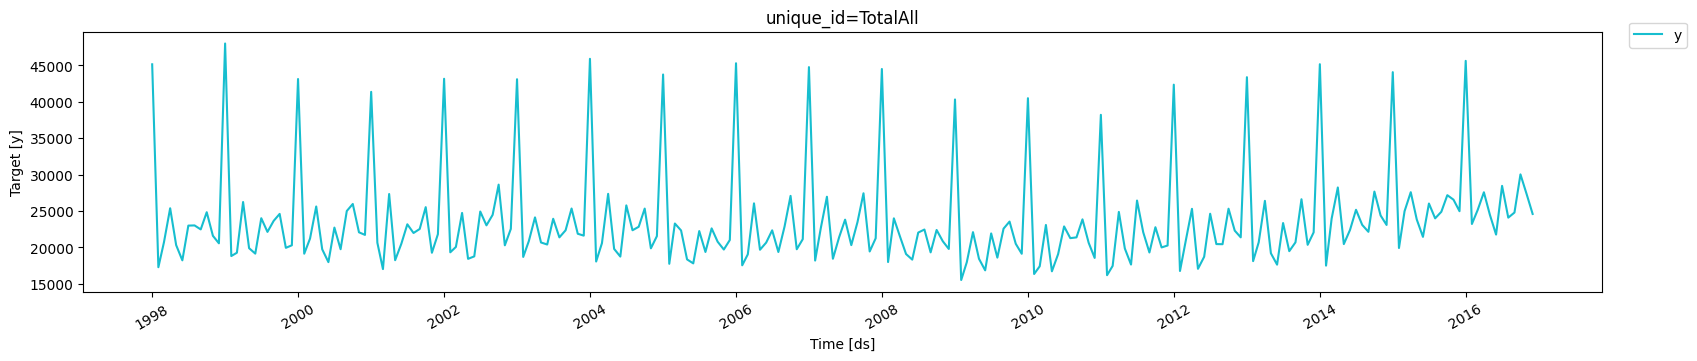

In [ ]:
plot_series(forecasts_df=Y_df[["unique_id", "ds", "y"]], ids=['TotalAll'])
# 讓你先看出「資料有什麼規律」，目前畫的是歷史資料
# 這張圖只是讓你觀察澳洲旅遊人數的歷史變化，不影響後續模型訓練

## 3. Fit and Predict HINT 主要重點

### 輸入輸出、資料切分、各模組的分工

分層預報網路（HINT）結合成一個易於使用的系統

模型三個組成部分：
     

*   SoTA 神經預測模型
*   一個高效且靈活的多變量機率分布
*   內建的對帳功能。

後面修改 GMM → PMM 會用到。但只需要知道三個模組的分工。

**SoTA（State of the Art）** *NHIT*
就是指先進的技術或模型，不是另一個需要安裝的套件，負責預測未來的數值。

**多變量機率分布** *(GMM／PMM)*
負責描述預測的不確定性，以及不同序列之間的關係。
之後要修改的 GMM → PMM，就是這一部分。

**對帳功能（Reconciliation）** *HINT*
負責讓不同階層的預測符合加總關係(一致性)


NHITS:時間序列預測模型

HINT:階層式機率預測框架

In [ ]:
import logging # 管理程式執行時的訊息

import numpy as np # 數值運算 像是矩陣

from neuralforecast import NeuralForecast # 管理模型的訓練、預測與執行流程
from neuralforecast.models import NHITS, HINT # N神經網路模型，學習時間序列規律並預測 H階層式機率預測框架，整合模型與階層協調
from neuralforecast.losses.pytorch import GMM, sCRPS # 評估機率預測品質的指標
from neuralforecast.losses.pytorch import PMM

In [ ]:
# 資料切割 以12(個月)為基礎
horizon = 12
Y_test_df  = Y_df.groupby('unique_id', observed=True).tail(horizon) # 依照時間序列 ID 分組，例如 A 店、B 店。
Y_train_df = Y_df.drop(Y_test_df.index)

# 每條時間序列"最後12個月"當測試資料，剩下的當訓練資料。

# 在這裡切出test(最後12筆) train(其他的) -> valid的話會後續階段從train切出來

import numpy as np

y = Y_train_df['y']

is_nonnegative = y >= 0
is_integer = np.isclose(y, np.round(y), rtol=0, atol=1e-8)
is_valid = is_nonnegative & is_integer & y.notna()


In [ ]:

print("總資料筆數:", len(y))
print("符合非負整數的筆數:", is_valid.sum())
print("不符合的筆數:", (~is_valid).sum())
print("符合比例:", f"{is_valid.mean():.2%}")

print("\n不符合的前 10 筆:")
print(Y_train_df.loc[~is_valid, ['unique_id', 'ds', 'y']].head(10))

y = Y_train_df['y']
y_round = y.round()

abs_error = (y - y_round).abs()
relative_error = abs_error / y.abs().replace(0, np.nan)

print("平均絕對誤差:", abs_error.mean())
print("最大絕對誤差:", abs_error.max())
print("平均相對誤差:", relative_error.mean())
print("相對誤差超過 1% 的筆數:",
      (relative_error > 0.01).sum())
print("正數被變成 0 的筆數:",
      ((y > 0) & (y_round == 0)).sum())


總資料筆數: 119880
符合非負整數的筆數: 13015
不符合的筆數: 106865
符合比例: 10.86%

不符合的前 10 筆:
  unique_id         ds             y
0  TotalAll 1998-01-01  45151.071280
1  TotalAll 1998-02-01  17294.699551
2  TotalAll 1998-03-01  20725.114184
3  TotalAll 1998-04-01  25388.612353
4  TotalAll 1998-05-01  20330.035211
5  TotalAll 1998-06-01  18237.554021
6  TotalAll 1998-07-01  23005.286680
7  TotalAll 1998-08-01  23032.504193
8  TotalAll 1998-09-01  22483.494361
9  TotalAll 1998-10-01  24844.924413
平均絕對誤差: 0.2226951457290637
最大絕對誤差: 0.49998350000001324
平均相對誤差: 0.02061994585048032
相對誤差超過 1% 的筆數: 26693
正數被變成 0 的筆數: 333


In [ ]:


import numpy as np

y = Y_train_df['y']

print("=== TourismLarge 資料特性 ===")
print("最小值:", y.min())
print("中位數:", y.median())
print("平均數:", y.mean())
print("最大值:", y.max())

print("\n零值比例:", f"{(y == 0).mean():.2%}")
print("小於 1 的比例:", f"{(y < 1).mean():.2%}")
print("小於 10 的比例:", f"{(y < 10).mean():.2%}")
print("小於 100 的比例:", f"{(y < 100).mean():.2%}")

print("\n各分位數:")
print(y.quantile([0, .01, .1, .5, .9, .99, 1]))


=== TourismLarge 資料特性 ===
最小值: 0.0
中位數: 60.7382878
平均數: 337.797099479019
最大值: 48008.85910060003

零值比例: 10.86%
小於 1 的比例: 12.04%
小於 10 的比例: 24.23%
小於 100 的比例: 59.64%

各分位數:
0.00        0.000000
0.01        0.000000
0.10        0.000000
0.50       60.738288
0.90      655.794277
0.99     4868.938296
1.00    48008.859101
Name: y, dtype: float64


In [ ]:
import inspect; print(inspect.signature(PMM))


(n_components=10, level=[80, 90], quantiles=None, num_samples=1000, return_params=False, batch_correlation=False, horizon_correlation=False, weighted=False)


In [ ]:
# Horizon and quantiles
level = np.arange(0, 100, 2) # 預測區間涵蓋率
qs = [[50-lv/2, 50+lv/2] if lv!=0 else [50] for lv in level]
quantiles = np.sort(np.concatenate(qs)/100)

# HINT := BaseNetwork + Distribution + Reconciliation
nhits = NHITS(h=horizon,# 模型要預測未來 12 個月*
              input_size=24,# 每次使用過去24個月的視窗 *
              loss=PMM(n_components=10, quantiles=quantiles, weighted=True),# 使用 10 個卜瓦松分布的混合成分 *
              # 改這裡 F改T
              hist_exog_list=['month'],# 月份當特徵
              max_steps=2000, # 最多執行 2,000 次訓練更新（不是 2,000 個 Epoch）
              early_stop_patience_steps=10, # 如果連續 10 次驗證檢查都沒有改善，就提早停止訓練
              val_check_steps=50,
              scaler_type='robust',# 資料標準化
              #learning_rate=0.0003,
              learning_rate=0.001,
              valid_loss=sCRPS(quantiles=quantiles)) # 驗證模型表現的指標

model = HINT(h=horizon, # *
             S=S_df.drop(columns='unique_id').values,# *
             model=nhits, # *
             reconciliation='BottomUp'# *
             )

# 因為每次是使用24個月的資料訓練 但訓練集又不一定是剛好24個月的資料 通常都是好幾年的 所以使用
# Sliding Window方法
# 例如：
# 第一次：用第 1～24 月，學習預測第 25～36 月。
# 第二次：用第 2～25 月，學習預測第 26～37 月。
# 第三次：用第 3～26 月，學習預測第 27～38 月。
# 依此類推，直到用第 13～36 月，學習預測第 37～48 月。
#因此這個例子中，單條時間序列就能建立 13 個完整的訓練視窗。input_size=24 限制的是模型每次看到的歷史長度

INFO:lightning_fabric.utilities.seed:Seed set to 1


In [ ]:
logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

In [ ]:
%%capture
Y_df['y'] = Y_df['y'] * (Y_df['y'] > 0)
nf = NeuralForecast(models=[model], freq='MS')
nf.fit(df=Y_train_df, val_size=12)# 從前面的資料尾端留出 12 個月做驗證 從這裡開始訓練
Y_hat_df = nf.predict() #進行預測

Y_hat_df = Y_hat_df.rename(columns=lambda x: x.replace('.0', ''))

In [ ]:

# 將 PMM 預測與真實值對齊
check = Y_hat_df.merge(
    Y_test_df[['unique_id', 'ds', 'y']],
    on=['unique_id', 'ds']
)

# 預測誤差
check['abs_error'] = (check['HINT'] - check['y']).abs()

print("=== PMM 預測值分布 ===")
print(check[['y', 'HINT', 'abs_error']].describe())

print("\n=== 預測誤差最大的 10 筆 ===")
print(
    check.nlargest(10, 'abs_error')[
        ['unique_id', 'ds', 'y', 'HINT', 'abs_error']
    ]
)
check['width_90'] = (
    check['HINT-hi-90'] - check['HINT-lo-90']
)

check['covered_90'] = (
    (check['y'] >= check['HINT-lo-90']) &
    (check['y'] <= check['HINT-hi-90'])
)

print("90% 區間平均寬度:", check['width_90'].mean())
print("90% 區間實際涵蓋率:", f"{check['covered_90'].mean():.2%}")

print("預測區間最寬的 10 筆:")
print(
    check.nlargest(10, 'width_90')[
        ['unique_id', 'ds', 'y',
         'HINT-lo-90', 'HINT-hi-90', 'width_90']
    ]
)

=== PMM 預測值分布 ===
                  y          HINT    abs_error
count   6660.000000   6660.000000  6660.000000
mean     393.008156    367.667201    67.483934
std     1537.070636   1439.849983   164.357995
min        0.000000      0.009000     0.005341
25%       15.289156     19.804375     7.747316
50%       75.996393     75.730531    23.392680
75%      269.964871    248.652863    66.512808
max    45625.487797  45535.371058  3650.600537

=== 預測誤差最大的 10 筆 ===
     unique_id         ds             y          HINT    abs_error
6     TotalAll 2016-07-01  28460.574755  24809.974218  3650.600537
10    TotalAll 2016-11-01  27320.918908  23850.767676  3470.151232
1338  TotalHol 2016-07-01  13229.862939   9938.204360  3291.658579
9     TotalAll 2016-10-01  30039.106985  26874.955100  3164.151886
1     TotalAll 2016-02-01  23227.928309  20074.020395  3153.907913
4     TotalAll 2016-05-01  24489.221902  21951.654635  2537.567267
2     TotalAll 2016-03-01  25156.548833  22672.965276  2483.583557
1

In [ ]:
print("=== PMM 平均值與中位數比較 ===")

print(
    check[['y', 'HINT', 'HINT-median']].describe()
)

print("\n=== 異常序列 ===")

ids = ['AAAAll', 'AABBus', 'ACAHol', 'BABOth']

print(
    check[check['unique_id'].isin(ids)]
    [['unique_id', 'ds', 'y', 'HINT', 'HINT-median']]
    .head(20)
    .to_string(index=False)
)

print("\n=== MAE 比較 ===")

print("平均預測 MAE:",
      (check['HINT'] - check['y']).abs().mean())

print("中位數預測 MAE:",
      (check['HINT-median'] - check['y']).abs().mean())

=== PMM 平均值與中位數比較 ===
                  y          HINT   HINT-median
count   6660.000000   6660.000000   6660.000000
mean     393.008156    367.667201    353.699157
std     1537.070636   1439.849983   1435.781622
min        0.000000      0.009000      0.000000
25%       15.289156     19.804375     12.000000
50%       75.996393     75.730531     63.000000
75%      269.964871    248.652863    230.914126
max    45625.487797  45535.371058  45509.931690

=== 異常序列 ===
unique_id         ds           y        HINT  HINT-median
   AAAAll 2016-01-01 2805.558269 3123.884337  3126.120003
   AAAAll 2016-02-01 1656.881882 1735.138321  1704.140991
   AAAAll 2016-03-01 1620.667434 1931.672775  1902.020508
   AAAAll 2016-04-01 2097.611197 2069.474512  2052.489532
   AAAAll 2016-05-01 2040.491524 1776.402057  1753.986008
   AAAAll 2016-06-01 1927.296981 1794.663902  1770.423004
   AAAAll 2016-07-01 1958.102387 1881.260478  1864.596054
   AAAAll 2016-08-01 2135.497646 1817.619783  1801.152998
   AAAAll 

圖表已生成，忽略套件版本造成的 KeyError，繼續執行後續程式碼。


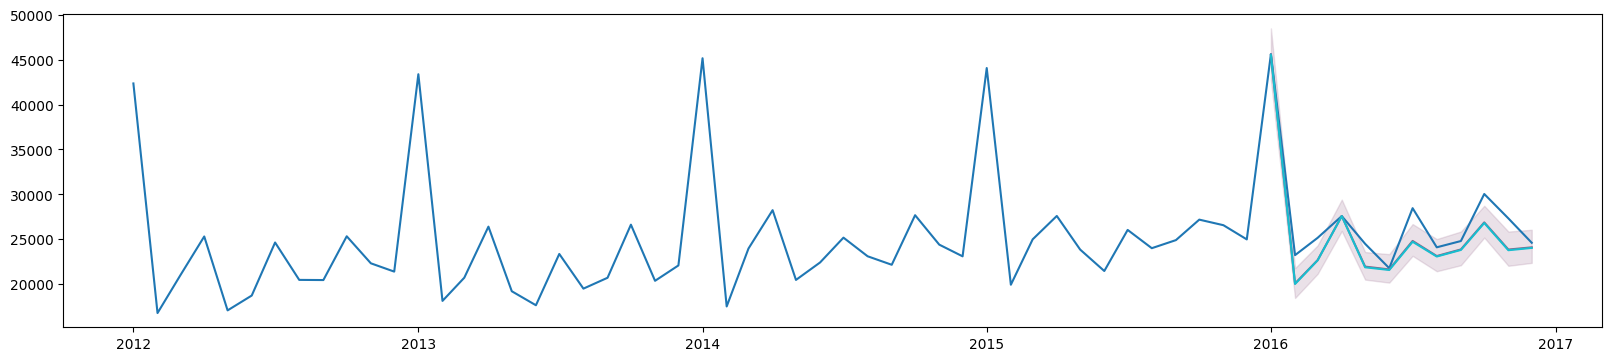

In [ ]:
try:
    plot_series(
        Y_df,
        Y_hat_df,
        ids=['TotalAll'],
        level=[90],
        max_insample_length=12*5,
    )
except KeyError:
    # 捕捉到 KeyError 時不中斷程式，只印出提示
    print("圖表已生成，忽略套件版本造成的 KeyError，繼續執行後續程式碼。")

## 4. Benchmark methods 懂用途與流程就好

### AutoARIMA 是比較對象；另外示範階層調整方法

We compare against AutoARIMA, a well-established traditional forecasting method from the [StatsForecast](../../../statsforecast/index.html) package, for which we reconcile the forecasts using [HierarchicalForecast](../../../hierarchicalforecast/index.html).

In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from hierarchicalforecast.methods import BottomUp, MinTrace
from hierarchicalforecast.core import HierarchicalReconciliation

We define the model, and create the forecasts.

In [ ]:
sf = StatsForecast(models=[AutoARIMA()],
                     freq='MS', n_jobs=-1)
Y_hat_df_arima = sf.forecast(df=Y_train_df,
                             h=12,# 是預測 接下來 12 個月。
                             fitted=True,
                             X_df=Y_test_df.drop(columns="y"),
                             level = np.arange(2, 100, 2))
Y_fitted_df_arima = sf.forecast_fitted_values()

/usr/local/lib/python3.13/dist-packages/statsforecast/core.py:1117: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[cols] = self.fcst_fitted_values_["values"]


Next, we reconcile the forecasts using `BottomUp` and `MinTrace` reconciliation techniques:

In [ ]:
reconcilers = [
    BottomUp(),
    MinTrace(method='mint_shrink'),
]
hrec = HierarchicalReconciliation(reconcilers=reconcilers)
Y_rec_df = hrec.reconcile(Y_hat_df=Y_hat_df_arima,
                          Y_df=Y_fitted_df_arima,
                          # S=S_df,
                          S_df=S_df,
                          tags=tags,
                          level = np.arange(2, 100, 2),
                          intervals_method="bootstrap")

## 5. Forecast Evaluation 一定要懂

### 預測與真實值怎麼對齊、分數怎麼解讀

To evaluate the coherent probabilistic predictions we use the scaled Continuous Ranked Probability Score (sCRPS), defined as follows:

$$
\mathrm{CRPS}(\hat{F}_{[a,b],\tau},\mathbf{y}_{[a,b],\tau}) =
    \frac{2}{N_{a}+N_{b}} \sum_{i} \int^{1}_{0} \mathrm{QL}(\hat{F}_{i,\tau}, y_{i,\tau})_{q} dq
$$

$$
\mathrm{sCRPS}(\hat{F}_{[a,b\,],\tau},\mathbf{y}_{[a,b\,],\tau}) =
    \frac{\mathrm{CRPS}(\hat{F}_{[a,b\,],\tau},\mathbf{y}_{[a,b\,],\tau})}{\sum_{i} | y_{i,\tau} |}
$$

As you can see the HINT model (using NHITS as base model) efficiently achieves state of the art accuracy under minimal tuning.

In [ ]:
from utilsforecast.losses import scaled_crps
from hierarchicalforecast.evaluation import evaluate

In [ ]:
import numpy as np
from utilsforecast.losses import scaled_crps
from hierarchicalforecast.evaluation import evaluate

# 合併預測結果與真實答案
df_metrics = Y_hat_df.merge(
    Y_test_df.drop(columns="month"),
    on=["unique_id", "ds"],
)
df_metrics = df_metrics.merge(
    Y_rec_df,
    on=["unique_id", "ds"],
)

# 讀取實際模型名稱，避免寫死 NHITS 或 HINT
model_name = str(nf.models[0])
print("這次評估的模型名稱：", model_name)

metrics = evaluate(
    df=df_metrics,
    tags=tags,
    metrics=[scaled_crps],
    models=[model_name, "AutoARIMA"],
    level=np.arange(2, 100, 2),
    train_df=Y_train_df.drop(columns="month"),
)

metrics

這次評估的模型名稱： HINT


,level,metric,HINT,AutoARIMA
0,Country,scaled_crps,0.053613,0.132560
1,Country/State,scaled_crps,0.102472,0.160529
2,Country/State/Zone,scaled_crps,0.142287,0.193033
3,Country/State/Zone/Region,scaled_crps,0.234517,0.278672
4,Country/Purpose,scaled_crps,0.080104,0.120363
5,Country/State/Purpose,scaled_crps,0.199202,0.232230
6,Country/State/Zone/Purpose,scaled_crps,0.319810,0.368543
7,Country/State/Zone/Region/Purpose,scaled_crps,0.696573,1.012140
8,Overall,scaled_crps,0.494832,0.688512


In [ ]:
metrics = evaluate(
    df = df_metrics,
    tags = tags,
    metrics = [scaled_crps],
    models = ["HINT", "AutoARIMA"],  # <--- 將 "NHITS" 改成 "HINT"
    level = np.arange(2, 100, 2),
    train_df = Y_train_df.drop(columns="month"),
)

In [ ]:
df_metrics = Y_hat_df.merge(Y_test_df.drop(columns="month"), on=['unique_id', 'ds'])
df_metrics = df_metrics.merge(Y_rec_df, on=['unique_id', 'ds'])

metrics = evaluate(df = df_metrics,
                    tags = tags,
                    metrics = [scaled_crps],
                    models= ["HINT", "AutoARIMA"],
                    level = np.arange(2, 100, 2),
                    train_df = Y_train_df.drop(columns="month"),
                    )

metrics

,level,metric,HINT,AutoARIMA
0,Country,scaled_crps,0.053613,0.132560
1,Country/State,scaled_crps,0.102472,0.160529
2,Country/State/Zone,scaled_crps,0.142287,0.193033
3,Country/State/Zone/Region,scaled_crps,0.234517,0.278672
4,Country/Purpose,scaled_crps,0.080104,0.120363
5,Country/State/Purpose,scaled_crps,0.199202,0.232230
6,Country/State/Zone/Purpose,scaled_crps,0.319810,0.368543
7,Country/State/Zone/Region/Purpose,scaled_crps,0.696573,1.012140
8,Overall,scaled_crps,0.494832,0.688512


## References

- [Kin G. Olivares, David Luo, Cristian Challu, Stefania La Vattiata, Max Mergenthaler, Artur Dubrawski (2023). "HINT: Hierarchical Mixture Networks For Coherent Probabilistic Forecasting". International Conference on Machine Learning (ICML). Workshop on Structured Probabilistic Inference & Generative Modeling. Available at https://arxiv.org/abs/2305.07089.](https://arxiv.org/abs/2305.07089)<br />
- [Kin G. Olivares, O. Nganba Meetei, Ruijun Ma, Rohan Reddy, Mengfei Cao, Lee Dicker (2023)."Probabilistic Hierarchical Forecasting with Deep Poisson Mixtures". International Journal Forecasting, accepted paper. URL https://arxiv.org/pdf/2110.13179.pdf.](https://arxiv.org/pdf/2110.13179.pdf)<br />
- [Kin G. Olivares, Federico Garza, David Luo, Cristian Challu, Max Mergenthaler, Souhaib Ben Taieb, Shanika Wickramasuriya, and Artur Dubrawski (2023). "HierarchicalForecast: A reference framework for hierarchical forecasting". Journal of Machine Learning Research, submitted. URL https://arxiv.org/abs/2207.03517](https://arxiv.org/abs/2207.03517)